# Part 2 - Evaluation (KID, CLIP score, LPIPS, grids, memorization, human eval, HF upload)

Runs on the images and adapters already produced by `p2_finetune.ipynb`; it does **not** retrain.
Run from the repository root (or `/workspace/lab2_package`) with **Restart & Run All**.

In [1]:
# Cell 1 - run information (required)
import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

{'commit': '4c38d6c', 'python': '3.10.13', 'torch': '2.1.2', 'gpu': 'NVIDIA GeForce RTX 4090', 'seed': 266}


In [2]:
# If missing: %pip install -q open_clip_torch==2.29.0 lpips==0.1.4 torchmetrics==1.6.0 torch-fidelity huggingface_hub
import json, time
from pathlib import Path
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

ROOT = Path.cwd()
for cand in [ROOT, ROOT.parent, Path("/app/DATA266-Lab2-Pair45"), Path("/workspace/lab2_package")]:
    if (cand / "part2_diffusion" / "generations").exists():
        ROOT = cand; break
OUT = ROOT / "part2_diffusion"
GEN = OUT / "generations"
TEST, TRAIN = OUT / "data" / "clean" / "test", OUT / "data" / "clean" / "train"
EVAL = OUT / "evaluation"; EVAL.mkdir(parents=True, exist_ok=True)
MODELS = ["base", "rank4", "rank16"]
FINAL = "rank4"            # run selected as final (also used in Part 3)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

prompts = json.loads((OUT / "prompts.json").read_text())
PROMPT = {p["prompt_id"]: p["prompt"] for p in prompts}
IN_DOMAIN, OUT_DOMAIN, COMPOSITIONAL = range(0, 10), range(10, 15), range(15, 20)

def gen_path(model, pid, seed):
    return GEN / model / f"prompt_{pid:02d}_seed_{seed}.png"

missing = [str(gen_path(m, p, s)) for m in MODELS for p in range(20) for s in (0, 1) if not gen_path(m, p, s).exists()]
print({"root": str(ROOT), "test_images": len(list(TEST.glob("*.png"))),
       "train_images": len(list(TRAIN.glob("*.png"))), "missing_generations": len(missing)})
assert not missing, missing[:5]

{'root': '/app/DATA266-Lab2-Pair45', 'test_images': 123, 'train_images': 1098, 'missing_generations': 0}


In [ ]:
import json, time
from pathlib import Path
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

ROOT = Path.cwd()
for cand in [ROOT, ROOT.parent, Path("/app/DATA266-Lab2-Pair45"), Path("/workspace/lab2_package")]:
    if (cand / "part2_diffusion" / "generations").exists():
        ROOT = cand; break
OUT = ROOT / "part2_diffusion"
GEN = OUT / "generations"
TEST, TRAIN = OUT / "data" / "clean" / "test", OUT / "data" / "clean" / "train"
EVAL = OUT / "evaluation"; EVAL.mkdir(parents=True, exist_ok=True)
MODELS = ["base", "rank4", "rank16"]
FINAL = "rank4"            # run selected as final (also used in Part 3)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

prompts = json.loads((OUT / "prompts.json").read_text())
PROMPT = {p["prompt_id"]: p["prompt"] for p in prompts}
IN_DOMAIN, OUT_DOMAIN, COMPOSITIONAL = range(0, 10), range(10, 15), range(15, 20)

def gen_path(model, pid, seed):
    return GEN / model / f"prompt_{pid:02d}_seed_{seed}.png"

missing = [str(gen_path(m, p, s)) for m in MODELS for p in range(20) for s in (0, 1) if not gen_path(m, p, s).exists()]
print({"root": str(ROOT), "test_images": len(list(TEST.glob("*.png"))),
       "train_images": len(list(TRAIN.glob("*.png"))), "missing_generations": len(missing)})
assert not missing, missing[:5]

## Black (NSFW-filtered) images

In [3]:
def is_black(path):
    return np.asarray(Image.open(path).convert("L")).max() < 5
black = {m: [(p, s) for p in range(20) for s in (0, 1) if is_black(gen_path(m, p, s))] for m in MODELS}
print({m: len(v) for m, v in black.items()})
print(black)

{'base': 0, 'rank4': 1, 'rank16': 4}
{'base': [], 'rank4': [(2, 1)], 'rank16': [(0, 1), (2, 1), (4, 0), (5, 0)]}


## Primary: CLIP score (prompt vs image) and KID (in-domain generations vs test images)

In [4]:
import open_clip
clip_model, _, clip_pre = open_clip.create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k", device=DEVICE)
clip_tok = open_clip.get_tokenizer("ViT-B-32"); clip_model.eval()

@torch.no_grad()
def img_emb(paths, bs=32):
    out = []
    for i in range(0, len(paths), bs):
        x = torch.stack([clip_pre(Image.open(p).convert("RGB")) for p in paths[i:i+bs]]).to(DEVICE)
        e = clip_model.encode_image(x).float(); out.append(e / e.norm(dim=-1, keepdim=True))
    return torch.cat(out)

@torch.no_grad()
def txt_emb(texts):
    e = clip_model.encode_text(clip_tok(texts).to(DEVICE)).float()
    return e / e.norm(dim=-1, keepdim=True)

rows = []
for m in MODELS:
    keys = [(p, s) for p in range(20) for s in (0, 1)]
    ie = img_emb([gen_path(m, p, s) for p, s in keys])
    te = txt_emb([PROMPT[p] for p, _ in keys])
    sims = (ie * te).sum(-1).cpu().numpy() * 100        # CLIPScore convention: 100 * cosine
    for (p, s), v in zip(keys, sims):
        rows.append({"model": m, "prompt_id": p, "seed": s, "clip_score": float(v),
                     "group": "in" if p < 10 else ("out" if p < 15 else "comp"), "black": (p, s) in black[m]})
clip_df = pd.DataFrame(rows); clip_df.to_csv(EVAL / "clip_scores.csv", index=False)
print(clip_df.pivot_table(index="model", columns="group", values="clip_score", aggfunc="mean").round(2))

/opt/conda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


group    comp     in    out
model                      
base    36.26  35.00  34.18
rank16  33.55  28.48  31.41
rank4   35.37  30.86  32.88


In [5]:
from torchmetrics.image.kid import KernelInceptionDistance
def load_uint8(paths, size=299):
    return torch.stack([torch.from_numpy(np.asarray(Image.open(p).convert("RGB").resize((size, size)))).permute(2, 0, 1) for p in paths])

test_imgs = load_uint8(sorted(TEST.glob("*.png")))
kid_rows = []
for m in MODELS:
    fake = load_uint8([gen_path(m, p, s) for p in IN_DOMAIN for s in (0, 1)])   # 20 images
    kid = KernelInceptionDistance(subset_size=20, subsets=100).to(DEVICE)
    torch.manual_seed(SEED)
    kid.update(test_imgs.to(DEVICE), real=True); kid.update(fake.to(DEVICE), real=False)
    mean, std = kid.compute()
    kid_rows.append({"model": m, "kid_mean": float(mean), "kid_std": float(std), "n_fake": len(fake), "n_real": len(test_imgs)})
kid_df = pd.DataFrame(kid_rows); kid_df.to_csv(EVAL / "kid.csv", index=False); print(kid_df)

/tmp/ipykernel_833/689252716.py:3: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /opt/conda/conda-bld/pytorch_1702400410390/work/torch/csrc/utils/tensor_numpy.cpp:206.)
  return torch.stack([torch.from_numpy(np.asarray(Image.open(p).convert("RGB").resize((size, size)))).permute(2, 0, 1) for p in paths])
/opt/conda/lib/python3.10/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)  # noqa: B028
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-incep

    model  kid_mean   kid_std  n_fake  n_real
0    base  0.172330  0.012532      20     123
1   rank4  0.035746  0.007419      20     123
2  rank16  0.051077  0.007491      20     123


## Secondary: diversity = LPIPS between seed 0 and seed 1 of each prompt

In [6]:
import lpips
lp = lpips.LPIPS(net="alex").to(DEVICE)
def to_t(p):
    a = np.asarray(Image.open(p).convert("RGB").resize((256, 256))).astype(np.float32) / 127.5 - 1
    return torch.from_numpy(a).permute(2, 0, 1)[None].to(DEVICE)
lrows = []
with torch.no_grad():
    for m in MODELS:
        for p in range(20):
            lrows.append({"model": m, "prompt_id": p, "lpips": float(lp(to_t(gen_path(m, p, 0)), to_t(gen_path(m, p, 1))))})
lpips_df = pd.DataFrame(lrows); lpips_df.to_csv(EVAL / "lpips.csv", index=False)
print(lpips_df.groupby("model").lpips.mean().round(4))

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth
100%|██████████| 233M/233M [00:17<00:00, 13.8MB/s] 


Loading model from: /opt/conda/lib/python3.10/site-packages/lpips/weights/v0.1/alex.pth
model
base      0.6478
rank16    0.7514
rank4     0.6943
Name: lpips, dtype: float64


## Efficiency and run table (trainable parameters from the saved adapters)

In [7]:
from safetensors.torch import load_file
run_rows = []
for m in ["rank4", "rank16"]:
    rm = json.loads((OUT / f"lora_{m}" / "run_metrics.json").read_text())
    w = load_file(str(OUT / f"lora_{m}" / "pytorch_lora_weights.safetensors"))
    run_rows.append({"run": m, "lora_rank": rm["rank"], "trainable_params": int(sum(t.numel() for t in w.values())),
                     "learning_rate": 1e-4, "steps": rm["steps"], "batch_size": "1 x 4 grad-accum",
                     "train_seconds": round(rm["seconds"], 1), "gpu_hours": round(rm["seconds"] / 3600, 3),
                     "peak_gpu_mem_gb_logged": rm["peak_gpu_memory_gb"]})
run_df = pd.DataFrame(run_rows); run_df.to_csv(EVAL / "run_table.csv", index=False); print(run_df.to_string(index=False))
print("Note: peak memory was logged as 0.0 because training ran in a subprocess.")

   run  lora_rank  trainable_params  learning_rate  steps       batch_size  train_seconds  gpu_hours  peak_gpu_mem_gb_logged
 rank4          4            797184         0.0001   1000 1 x 4 grad-accum         2099.3      0.583                     0.0
rank16         16           3188736         0.0001   1000 1 x 4 grad-accum         2029.9      0.564                     0.0
Note: peak memory was logged as 0.0 because training ran in a subprocess.


## Results table (base vs final)

In [8]:
summary = []
for m in MODELS:
    c = clip_df[clip_df.model == m]
    summary.append({"model": m,
                    "KID_in_domain": round(float(kid_df.set_index("model").loc[m, "kid_mean"]), 4),
                    "CLIP_all": round(c.clip_score.mean(), 2), "CLIP_in": round(c[c.group == "in"].clip_score.mean(), 2),
                    "CLIP_out": round(c[c.group == "out"].clip_score.mean(), 2), "CLIP_comp": round(c[c.group == "comp"].clip_score.mean(), 2),
                    "LPIPS_diversity": round(lpips_df[lpips_df.model == m].lpips.mean(), 4),
                    "black_images": len(black[m]),
                    "GPU_hours": "-" if m == "base" else float(run_df.set_index("run").loc[m, "gpu_hours"])})
summary_df = pd.DataFrame(summary); summary_df.to_csv(EVAL / "results_table.csv", index=False)
print(summary_df.to_string(index=False))

 model  KID_in_domain  CLIP_all  CLIP_in  CLIP_out  CLIP_comp  LPIPS_diversity  black_images GPU_hours
  base         0.1723     35.11    35.00     34.18      36.26           0.6478             0         -
 rank4         0.0357     32.49    30.86     32.88      35.37           0.6943             1     0.583
rank16         0.0511     30.48    28.48     31.41      33.55           0.7514             4     0.564


## Side-by-side grids (base | rank 4 | rank 16) for 8 prompts

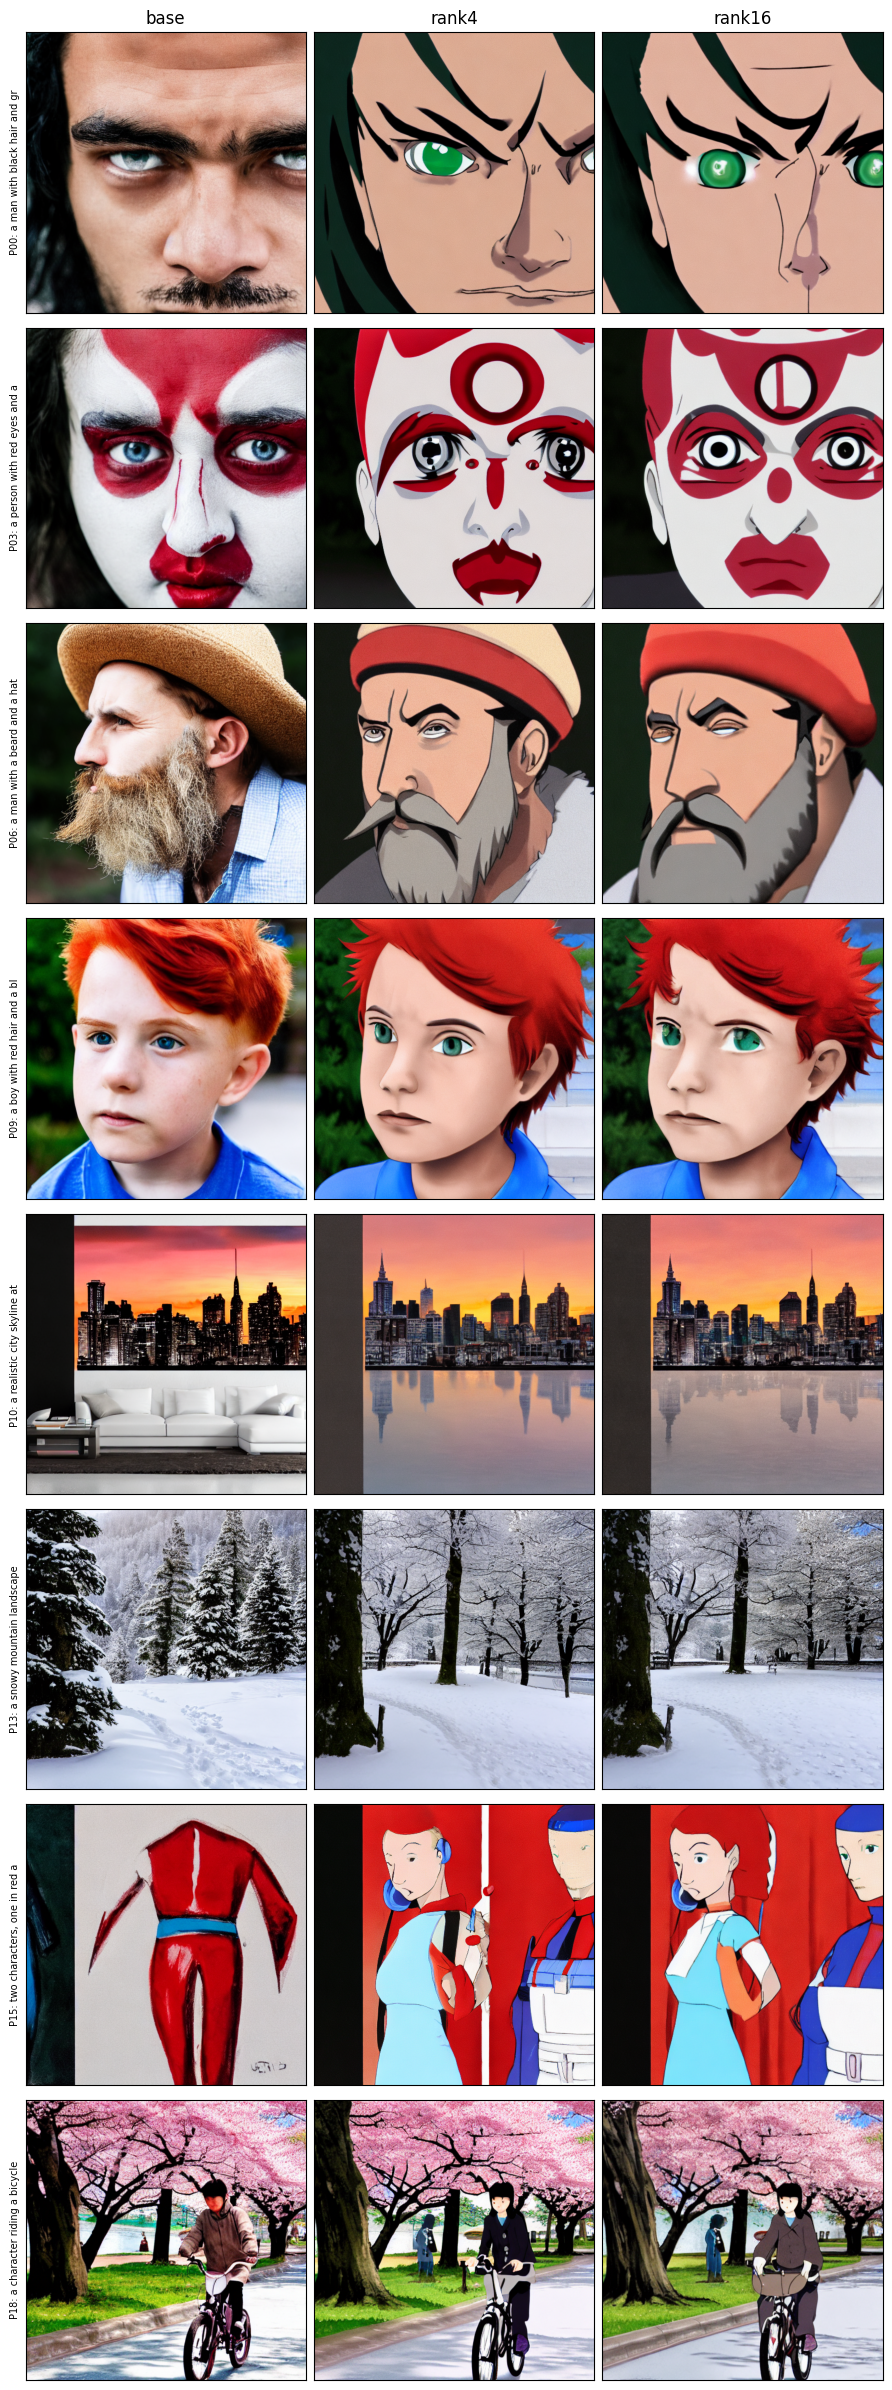

In [9]:
GRID_PROMPTS = [0, 3, 6, 9, 10, 13, 15, 18]   # 4 in-domain, 2 out-of-domain, 2 compositional
fig, axes = plt.subplots(len(GRID_PROMPTS), 3, figsize=(9, 3 * len(GRID_PROMPTS)))
for r, p in enumerate(GRID_PROMPTS):
    for c, m in enumerate(MODELS):
        ax = axes[r, c]; ax.imshow(Image.open(gen_path(m, p, 0))); ax.set_xticks([]); ax.set_yticks([])
        if r == 0: ax.set_title(m)
        if c == 0: ax.set_ylabel(f"P{p:02d}: {PROMPT[p][:28]}", fontsize=7)
plt.tight_layout(); plt.savefig(EVAL / "grid_base_rank4_rank16.png", dpi=110); plt.show()

## Memorization check: 10 in-domain final-model images vs nearest training image (CLIP)

           generated closest_train_image  clip_similarity
prompt_00_seed_0.png     image_00526.png           0.7936
prompt_04_seed_0.png     image_00010.png           0.7514
prompt_05_seed_0.png     image_00992.png           0.7428
prompt_06_seed_0.png     image_00645.png           0.7384
prompt_07_seed_0.png     image_01067.png           0.6995
prompt_08_seed_0.png     image_01045.png           0.6921
prompt_09_seed_0.png     image_00205.png           0.6421
prompt_03_seed_0.png     image_00573.png           0.6326
prompt_02_seed_0.png     image_00954.png           0.6175
prompt_01_seed_0.png     image_00742.png           0.3841


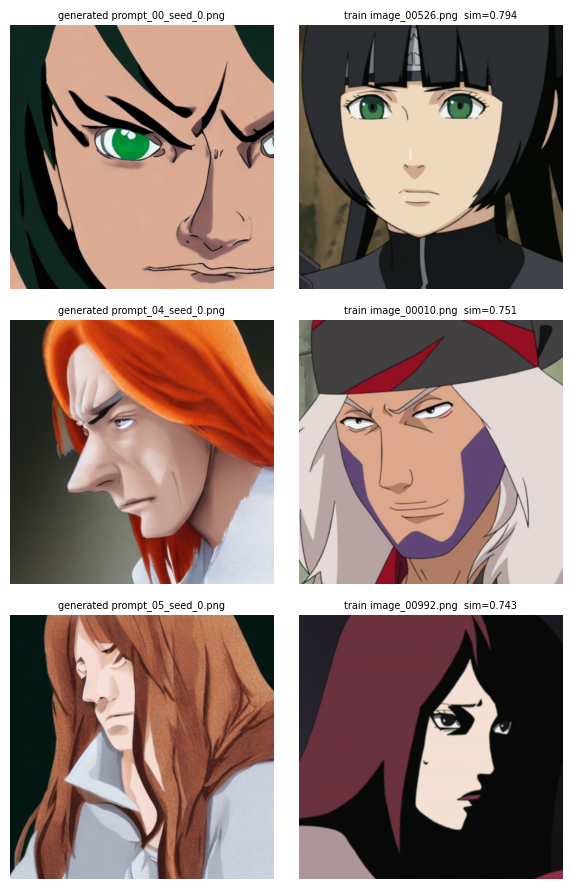

In [10]:
train_paths = sorted(TRAIN.glob("*.png"))
train_e = img_emb(train_paths)
q_paths = [gen_path(FINAL, p, 0) for p in IN_DOMAIN]
q_e = img_emb(q_paths)
sim = (q_e @ train_e.T).cpu().numpy()
mem = pd.DataFrame({"generated": [q.name for q in q_paths],
                    "closest_train_image": [train_paths[i].name for i in sim.argmax(1)],
                    "clip_similarity": sim.max(1).round(4)}).sort_values("clip_similarity", ascending=False)
mem.to_csv(EVAL / "memorization_check.csv", index=False); print(mem.to_string(index=False))
top3 = mem.head(3)
fig, axes = plt.subplots(3, 2, figsize=(6, 9))
for r, (_, row) in enumerate(top3.iterrows()):
    axes[r, 0].imshow(Image.open(GEN / FINAL / row.generated)); axes[r, 0].set_title(f"generated {row.generated}", fontsize=7)
    axes[r, 1].imshow(Image.open(TRAIN / row.closest_train_image)); axes[r, 1].set_title(f"train {row.closest_train_image}  sim={row.clip_similarity:.3f}", fontsize=7)
    for a in axes[r]: a.axis("off")
plt.tight_layout(); plt.savefig(EVAL / "memorization_top3.png", dpi=110); plt.show()

In [19]:
import pandas as pd, io
from pathlib import Path
HE = Path("/app/DATA266-Lab2-Pair45/part2_diffusion/evaluation/human_eval")
csv_text = """pair_id,style_better,prompt_match_better
0,B,A
1,B,B
2,A,A
3,A,B
4,A,B
5,B,A
6,A,B
7,A,A
8,A,B
9,B,B
10,B,A
11,B,B
12,A,A
13,A,A
14,A,A
15,B,B
16,A,A
17,B,B
18,A,A
19,A,A
20,B,B
21,B,B
22,A,A
23,B,B
24,A,A"""
pd.read_csv(io.StringIO(csv_text)).to_csv(HE / "human_eval_ratings_nikhil.csv", index=False)
print("saved", HE / "human_eval_ratings_nikhil.csv")

saved /app/DATA266-Lab2-Pair45/part2_diffusion/evaluation/human_eval/human_eval_ratings_nikhil.csv


In [20]:
import pandas as pd, io
from pathlib import Path

HE = Path("/app/DATA266-Lab2-Pair45/part2_diffusion/evaluation/human_eval")

csv_text = """pair_id,style_better,prompt_match_better
0,B,A
1,B,B
2,A,A
3,B,A
4,A,B
5,B,A
6,A,B
7,A,A
8,B,A
9,B,B
10,B,A
11,B,B
12,B,B
13,A,A
14,A,A
15,B,B
16,A,A
17,A,A
18,A,A
19,A,A
20,B,B
21,B,B
22,A,A
23,A,A
24,A,A"""

pd.read_csv(io.StringIO(csv_text)).to_csv(
    HE / "human_eval_ratings_samrudhi.csv",
    index=False
)

print("saved", HE / "human_eval_ratings_samrudhi.csv")

saved /app/DATA266-Lab2-Pair45/part2_diffusion/evaluation/human_eval/human_eval_ratings_samrudhi.csv


In [21]:
import pandas as pd, io
from pathlib import Path

HE = Path("/app/DATA266-Lab2-Pair45/part2_diffusion/evaluation/human_eval")

csv_text = """pair_id,style_better,prompt_match_better
0,B,A
1,B,B
2,A,A
3,B,A
4,A,B
5,B,A
6,A,B
7,A,A
8,A,B
9,B,B
10,B,A
11,B,B
12,A,A
13,A,A
14,A,A
15,B,B
16,A,A
17,B,B
18,A,A
19,A,A
20,B,B
21,B,B
22,A,A
23,B,B
24,A,A"""

pd.read_csv(io.StringIO(csv_text)).to_csv(
    HE / "human_eval_ratings_abhijith.csv",
    index=False
)

print("saved", HE / "human_eval_ratings_abhijith.csv")

saved /app/DATA266-Lab2-Pair45/part2_diffusion/evaluation/human_eval/human_eval_ratings_abhijith.csv


## Human evaluation (blind, 25 pairs, final vs base)

1. Run the next cell: it writes `evaluation/human_eval/pair_XX.png` (A = left, B = right, randomized) and a hidden key.
2. Each rater (both members + one outside person) fills a copy of `human_eval_ratings_TEMPLATE.csv`
   -> `human_eval_ratings_<name>.csv`, choosing `A` or `B` for style and for prompt match.
3. Run the cell after it to compute win rates.

In [22]:
HE = EVAL / "human_eval"; HE.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)
pairs = [(p, s) for p in range(20) for s in (0, 1)]
chosen = [pairs[i] for i in sorted(rng.choice(len(pairs), 25, replace=False))]
key = []
for i, (p, s) in enumerate(chosen):
    final_left = bool(rng.integers(0, 2))
    left, right = (FINAL, "base") if final_left else ("base", FINAL)
    canvas = Image.new("RGB", (1034, 560), "white")
    canvas.paste(Image.open(gen_path(left, p, s)).resize((512, 512)), (0, 48))
    canvas.paste(Image.open(gen_path(right, p, s)).resize((512, 512)), (522, 48))
    from PIL import ImageDraw
    ImageDraw.Draw(canvas).text((8, 8), f"Pair {i:02d}  |  Prompt: {PROMPT[p][:110]}   (A = left, B = right)", fill="black")
    canvas.save(HE / f"pair_{i:02d}.png")
    key.append({"pair_id": i, "prompt_id": p, "seed": s, "A_model": left, "B_model": right})
pd.DataFrame(key).to_csv(HE / "key_DO_NOT_SHOW_RATERS.csv", index=False)
pd.DataFrame({"pair_id": range(25), "style_better": "", "prompt_match_better": ""}).to_csv(HE / "human_eval_ratings_TEMPLATE.csv", index=False)
print("Wrote", len(key), "pairs to", HE)

Wrote 25 pairs to /app/DATA266-Lab2-Pair45/part2_diffusion/evaluation/human_eval


In [23]:
key_df = pd.read_csv(HE / "key_DO_NOT_SHOW_RATERS.csv")
files = sorted(HE.glob("human_eval_ratings_*.csv")); files = [f for f in files if "TEMPLATE" not in f.name]
res = []
for f in files:
    r = pd.read_csv(f, dtype=str).merge(key_df, on="pair_id")
    for crit in ["style_better", "prompt_match_better"]:
        picked = np.where(r[crit].str.strip().str.upper() == "A", r.A_model, r.B_model)
        res.append({"rater": f.stem.replace("human_eval_ratings_", ""), "criterion": crit,
                    "final_win_rate": float((picked == FINAL).mean()), "n": len(r)})
he_df = pd.DataFrame(res)
if len(he_df):
    he_df.to_csv(EVAL / "human_eval_results.csv", index=False); print(he_df.to_string(index=False))
    print(he_df.groupby("criterion").final_win_rate.mean().round(3))
else:
    print("No rating files yet - add human_eval_ratings_<name>.csv files and re-run this cell.")

ValueError: You are trying to merge on object and int64 columns for key 'pair_id'. If you wish to proceed you should use pd.concat

## Upload adapters and images to Hugging Face

Run `huggingface-cli login` (or `from huggingface_hub import login; login()`) first, and set `HF_USER`.

In [ ]:
HF_USER = "NikhilKanaparthi"
UPLOAD = False                   # <- set True to upload
if UPLOAD:
    from huggingface_hub import HfApi
    api = HfApi()
    for m in ["rank4", "rank16"]:
        repo = f"{HF_USER}/data266-lab2-team45-naruto-lora-{m}"
        api.create_repo(repo, exist_ok=True)
        api.upload_file(path_or_fileobj=str(OUT / f"lora_{m}" / "pytorch_lora_weights.safetensors"),
                        path_in_repo="pytorch_lora_weights.safetensors", repo_id=repo)
        print("model:", f"https://huggingface.co/{repo}")
    meta = []
    for m in MODELS:
        for p in range(20):
            for s in (0, 1):
                meta.append({"file_name": f"{m}/prompt_{p:02d}_seed_{s}.png", "model": m, "prompt_id": p, "prompt": PROMPT[p], "seed": s,
                             "steps": 30, "guidance_scale": 7.5})
    pd.DataFrame(meta).to_csv(GEN / "metadata.csv", index=False)
    ds = f"{HF_USER}/data266-lab2-team45-generations"
    api.create_repo(ds, repo_type="dataset", exist_ok=True)
    api.upload_folder(folder_path=str(GEN), repo_id=ds, repo_type="dataset", allow_patterns=["*.png", "metadata.csv"])
    print("dataset:", f"https://huggingface.co/datasets/{ds}")